In [1]:
import geopandas as gpd
from pathlib import Path

RAW = Path("../data/raw/limites")
for f in RAW.glob("*.zip"):
    print(f.name)

Barrios.zip
Distritos.zip
Secciones_Censales.zip


Para qué sirve este notebook

Todo el proyecto gira alrededor de una pregunta: en qué barrio vivir. Para responderla necesitamos un "mapa base" de Madrid, troceado en zonas, al que luego pegaremos datos: precios, transporte, ocio... Este notebook construye ese mapa base a tres escalas:

Escala	Cuántas	Para qué la usamos
Distritos	21	Mapas generales y validar el modelo de precios
Barrios	131	La unidad que recomienda la app
Secciones censales	2.462	Donde vienen los precios del alquiler y los datos del INE

Las secciones censales son las zonas más pequeñas que usa la estadística oficial en España (cada una tiene entre unas 1.000 y 2.500 personas). Casi todos los datos oficiales (precios, renta, edad) vienen por sección, así que son la pieza que conecta los datos con los barrios.

Celdas 1–4: cargar y ver los barrios
Shapefile dentro de un ZIP. El Ayuntamiento publica los límites como shapefile, el formato clásico de datos geográficos: varios archivos (.shp, .dbf, .prj...) que juntos guardan las formas y su tabla de datos. Con zip:// GeoPandas lo lee directamente del ZIP, sin descomprimir.
GeoDataFrame. Es un DataFrame de pandas normal con una columna especial, geometry, que guarda el polígono de cada barrio. Todo lo que sabes de pandas sigue valiendo.
CRS EPSG:25830. Es el sistema de coordenadas: dice cómo interpretar los números de los polígonos. El 25830 es UTM zona 30 (el estándar en España) y está en metros. Por eso luego pudimos calcular áreas en km² directamente. Si estuviera en latitud/longitud (EPSG:4326), las áreas saldrían en "grados al cuadrado" y no tendrían sentido.
Los mapas. plot() dibuja un mapa estático con matplotlib; explore() genera un mapa interactivo con Folium (Leaflet), que guardamos en HTML porque VS Code lo bloqueaba.
Celdas 5–7: limpiar y guardar los barrios
Quedarnos con lo útil. La tabla original traía el nombre tres veces y el código de distrito dos. Dejamos solo cod_distrito, distrito, cod_barrio, barrio y la geometría, con nombres en minúscula y claros.
Códigos como texto con zfill. Un código como 011 es un identificador, no un número: si lo guardas como número pierdes el cero y se convierte en 11, que ya no casa con otras fuentes. Por eso lo pasamos a texto rellenando ceros ("1" → "01"). Es uno de los errores más típicos al cruzar datos oficiales.
Comprobaciones (celda 6). Antes de seguir verificamos que hay 131 barrios y 21 distritos, que no hay códigos repetidos, que todas las geometrías son válidas y que la superficie suma los 604 km² de Madrid. Si algo falla, lo ves aquí y no tres pasos después.
GeoParquet. Guardamos en data/processed/barrios.parquet. Ocupa menos, se lee más rápido que el shapefile y conserva el CRS. Desde ahora el proyecto trabaja con este archivo y el ZIP queda como dato bruto que no se toca.
Celdas 8–11: secciones y cruce espacial
Mismo CRS. Antes de cruzar dos capas hay que asegurarse de que usan el mismo sistema de coordenadas (to_crs). Si no, los polígonos no se superponen bien y el cruce falla en silencio.
Punto representativo. Para saber en qué barrio está cada sección, la convertimos en un punto que esté seguro dentro de ella. Usamos representative_point() y no el centroide, porque en formas raras (en "L" o en "U") el centroide puede caer fuera del polígono.
Spatial join (sjoin). Es como un merge de pandas, pero en vez de unir por una columna común, une por posición: "a cada punto, pégale los datos del barrio en el que cae". Es la operación central de cualquier análisis geoespacial.
Recuento por barrio. Vimos que la media es de unas 19 secciones por barrio, y detectamos que Aeropuerto, Atalaya y Atocha tienen una sola sección: barrios casi sin viviendas que habrá que tratar con cuidado en el recomendador.
Mapa de comprobación. Dibujar barrios y secciones superpuestos es la validación visual: si las líneas grises cruzaran las negras, algo estaría mal.
Celdas 12–15: código INE, validación y guardado
Código INE de 10 dígitos. Construimos cod_seccion_ine = provincia (28) + municipio (079) + distrito (2) + sección (3). Es la llave con la que uniremos las secciones con los precios del SERPAVI y los datos del INE.
Doble validación. El fichero de secciones ya traía su barrio, y nosotros lo habíamos calculado por cruce espacial. Comparar los dos es una forma de comprobar que los datos y nuestro método son coherentes. Si coinciden, nos podemos fiar de los dos.
Guardado. Tres archivos limpios en data/processed/: barrios.parquet, distritos.parquet y secciones.parquet.

In [2]:
zip_barrios = [f for f in RAW.glob("*.zip") if "arrio" in f.name][0]
barrios = gpd.read_file(f"zip://{zip_barrios}")

print(barrios.shape)
print(barrios.crs)
barrios.head()

(131, 11)
EPSG:25830


,CODDIS,NOMDIS,COD_BAR,NOMBRE,COD_DIS_TX,BARRIO_MAY,COD_DISBAR,NUM_BAR,BARRIO_MT,AREA,geometry
0,17,Villaverde,171,Villaverde Alto - Casco Histórico de Villaverde,17,VILLAVERDE ALTO - CASCO HISTORICO DE VILLAVERDE,171,1,VILLAVERDE ALTO - CASCO HISTÓRICO DE VILLAVERDE,9.254048e+06,"POLYGON ((441017.489 4466354.375, 441050.818 4..."
1,17,Villaverde,172,San Cristóbal,17,SAN CRISTOBAL,172,2,SAN CRISTÓBAL,1.082492e+06,"POLYGON ((441224.682 4464925.894, 441171.808 4..."
2,17,Villaverde,173,Butarque,17,BUTARQUE,173,3,BUTARQUE,6.381764e+06,"POLYGON ((444144.707 4464513.034, 444144.856 4..."
3,17,Villaverde,174,Los Rosales,17,LOS ROSALES,174,4,LOS ROSALES,1.540747e+06,"POLYGON ((441941.844 4466974.287, 441930.867 4..."
4,17,Villaverde,175,Ángeles,17,ANGELES,175,5,ÁNGELES,1.935272e+06,"POLYGON ((441076.001 4468448.76, 441105.538 44..."


Text(0.5, 1.0, 'Barrios de Madrid')

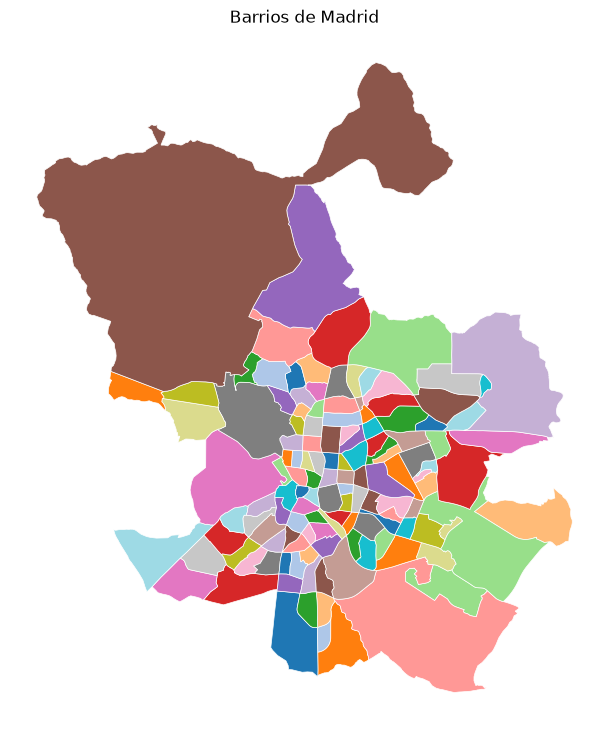

In [3]:
ax = barrios.plot(figsize=(9, 9), edgecolor="white", linewidth=0.5, cmap="tab20", column=barrios.index % 20)
ax.set_axis_off()
ax.set_title("Barrios de Madrid")

In [6]:
m = barrios.explore(column="NOMDIS", tooltip=["NOMBRE", "NOMDIS"])
m.save("../data/interim/mapa_barrios.html")

In [7]:
barrios_limpio = (
    barrios[["CODDIS", "NOMDIS", "COD_BAR", "NOMBRE", "geometry"]]
    .rename(columns={
        "CODDIS": "cod_distrito",
        "NOMDIS": "distrito",
        "COD_BAR": "cod_barrio",
        "NOMBRE": "barrio",
    })
)

# Códigos como texto con ceros a la izquierda: "01", "011"
barrios_limpio["cod_distrito"] = barrios_limpio["cod_distrito"].astype(int).astype(str).str.zfill(2)
barrios_limpio["cod_barrio"] = barrios_limpio["cod_barrio"].astype(int).astype(str).str.zfill(3)

# Superficie en km² (el CRS está en metros)
barrios_limpio["area_km2"] = barrios_limpio.geometry.area / 1e6

barrios_limpio.head()

,cod_distrito,distrito,cod_barrio,barrio,geometry,area_km2
0,17,Villaverde,171,Villaverde Alto - Casco Histórico de Villaverde,"POLYGON ((441017.489 4466354.375, 441050.818 4...",9.254048
1,17,Villaverde,172,San Cristóbal,"POLYGON ((441224.682 4464925.894, 441171.808 4...",1.082492
2,17,Villaverde,173,Butarque,"POLYGON ((444144.707 4464513.034, 444144.856 4...",6.381764
3,17,Villaverde,174,Los Rosales,"POLYGON ((441941.844 4466974.287, 441930.867 4...",1.540747
4,17,Villaverde,175,Ángeles,"POLYGON ((441076.001 4468448.76, 441105.538 44...",1.935272


In [8]:
print("Barrios:", len(barrios_limpio))                                   # 131
print("Distritos:", barrios_limpio["cod_distrito"].nunique())           # 21
print("Códigos de barrio únicos:", barrios_limpio["cod_barrio"].is_unique)  # True
print("Geometrías válidas:", barrios_limpio.is_valid.all())             # True
print("Superficie total (km²):", round(barrios_limpio["area_km2"].sum(), 1))  # ~604

Barrios: 131
Distritos: 21
Códigos de barrio únicos: True
Geometrías válidas: True
Superficie total (km²): 604.0


In [9]:
from pathlib import Path

PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

barrios_limpio.to_parquet(PROCESSED / "barrios.parquet")
print("Guardado:", PROCESSED / "barrios.parquet")

Guardado: ..\data\processed\barrios.parquet


In [10]:
zip_distritos = [f for f in RAW.glob("*.zip") if "istrit" in f.name][0]
zip_secciones = [f for f in RAW.glob("*.zip") if "ecci" in f.name][0]

distritos = gpd.read_file(f"zip://{zip_distritos}")
secciones = gpd.read_file(f"zip://{zip_secciones}")

print("Distritos:", distritos.shape, distritos.crs)
print(distritos.columns.tolist())
print()
print("Secciones:", secciones.shape, secciones.crs)
print(secciones.columns.tolist())
secciones.head()

Distritos: (21, 7) EPSG:25830
['COD_DIS', 'COD_DIS_TX', 'NOMBRE', 'DISTRI_MAY', 'DISTRI_MT', 'AREA', 'geometry']

Secciones: (2462, 7) EPSG:25830
['COD_DIS', 'NOM_DIS', 'COD_BAR', 'NOM_BAR', 'COD_SECCIO', 'AREA', 'geometry']


,COD_DIS,NOM_DIS,COD_BAR,NOM_BAR,COD_SECCIO,AREA,geometry
0,17,Villaverde,171,"Villaverde alto, Casco Histórico de Villaverde",17120,1.712583e+05,"POLYGON ((441169.497 4465067.449, 440908.086 4..."
1,17,Villaverde,172,San Cristóbal,17042,2.233715e+04,"POLYGON ((441660.649 4465831.887, 441715.328 4..."
2,17,Villaverde,172,San Cristóbal,17041,4.850937e+05,"POLYGON ((441549.769 4465831.988, 441551.448 4..."
3,17,Villaverde,172,San Cristóbal,17039,5.136459e+04,"POLYGON ((441203.193 4465933.861, 441276.782 4..."
4,17,Villaverde,173,Butarque,17117,4.283598e+06,"POLYGON ((444144.856 4464473.21, 443940.236 44..."


Asignamos cada seccion a  su barrio es un cruce especial 

In [11]:
secciones = secciones.to_crs(barrios_limpio.crs)

puntos = secciones.copy()
puntos["geometry"] = secciones.representative_point()

cruce = gpd.sjoin(
    puntos,
    barrios_limpio[["cod_barrio", "barrio", "cod_distrito", "distrito", "geometry"]],
    how="left",
    predicate="within",
)

print("Secciones:", len(secciones))
print("Sin barrio asignado:", cruce["cod_barrio"].isna().sum())   # debería ser 0
print("Asignadas a más de un barrio:", cruce.index.duplicated().sum())  # debería ser 0

Secciones: 2462
Sin barrio asignado: 0
Asignadas a más de un barrio: 0


In [ ]:
#numero de secciones por barrio 
por_barrio = cruce.groupby("barrio").size().sort_values()
print(por_barrio.describe())
print("\nBarrios con menos secciones:")
print(por_barrio.head(5))
print("\nBarrios con más secciones:")
print(por_barrio.tail(5))

count    131.000000
mean      18.793893
std       10.748680
min        1.000000
25%       11.000000
50%       17.000000
75%       26.000000
max       57.000000
dtype: float64

Barrios con menos secciones:
barrio
Aeropuerto        1
Atalaya           1
Atocha            1
El Plantío        2
Fuentelarreina    3
dtype: int64

Barrios con más secciones:
barrio
Águilas         42
Valverde        43
Pilar           44
Pueblo Nuevo    46
Aluche          57
dtype: int64


Text(0.5, 1.0, 'Barrios (negro) y secciones censales (gris)')

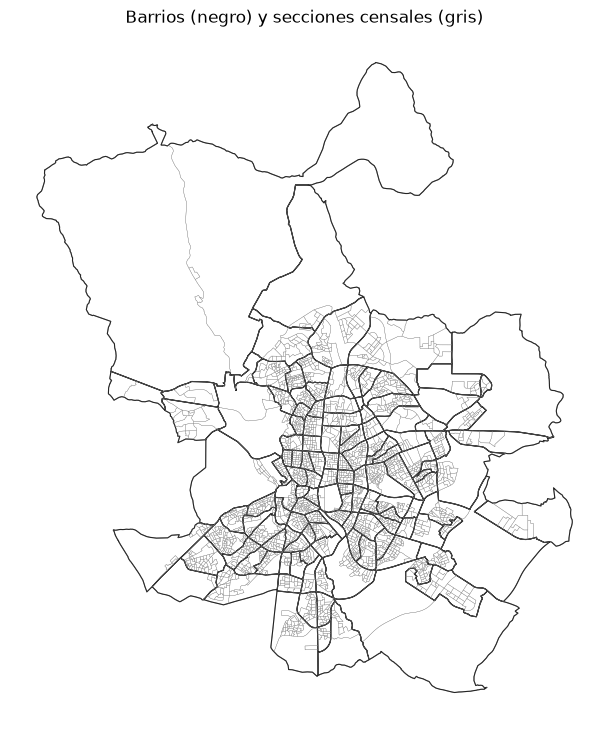

In [13]:
ax = barrios_limpio.boundary.plot(figsize=(9, 9), color="black", linewidth=0.8)
secciones.boundary.plot(ax=ax, color="grey", linewidth=0.2)
ax.set_axis_off()
ax.set_title("Barrios (negro) y secciones censales (gris)")

In [14]:
secciones_limpio = secciones[["COD_DIS", "COD_BAR", "COD_SECCIO", "geometry"]].copy()

secciones_limpio["cod_distrito"] = secciones_limpio["COD_DIS"].astype(int).astype(str).str.zfill(2)
secciones_limpio["cod_barrio"] = secciones_limpio["COD_BAR"].astype(int).astype(str).str.zfill(3)
secciones_limpio["cod_seccion"] = secciones_limpio["COD_SECCIO"].astype(int).astype(str).str.zfill(5)
secciones_limpio["cod_seccion_ine"] = "28079" + secciones_limpio["cod_seccion"]
secciones_limpio["area_km2"] = secciones_limpio.geometry.area / 1e6

secciones_limpio = secciones_limpio[["cod_seccion_ine", "cod_seccion", "cod_barrio", "cod_distrito", "area_km2", "geometry"]]
secciones_limpio.head()

,cod_seccion_ine,cod_seccion,cod_barrio,cod_distrito,area_km2,geometry
0,2807917120,17120,171,17,0.171258,"POLYGON ((441169.497 4465067.449, 440908.086 4..."
1,2807917042,17042,172,17,0.022337,"POLYGON ((441660.649 4465831.887, 441715.328 4..."
2,2807917041,17041,172,17,0.485094,"POLYGON ((441549.769 4465831.988, 441551.448 4..."
3,2807917039,17039,172,17,0.051365,"POLYGON ((441203.193 4465933.861, 441276.782 4..."
4,2807917117,17117,173,17,4.283598,"POLYGON ((444144.856 4464473.21, 443940.236 44..."


In [15]:
comparacion = secciones_limpio[["cod_seccion_ine", "cod_barrio"]].join(
    cruce["cod_barrio"].rename("cod_barrio_espacial")
)

coinciden = (comparacion["cod_barrio"] == comparacion["cod_barrio_espacial"])
print("Secciones:", len(comparacion))
print("Coinciden:", coinciden.sum())
print("No coinciden:", (~coinciden).sum())
print("Códigos INE únicos:", secciones_limpio["cod_seccion_ine"].is_unique)
print("Todos con 10 dígitos:", secciones_limpio["cod_seccion_ine"].str.len().eq(10).all())

comparacion[~coinciden].head(10)

Secciones: 2462
Coinciden: 2462
No coinciden: 0
Códigos INE únicos: True
Todos con 10 dígitos: True


,cod_seccion_ine,cod_barrio,cod_barrio_espacial


In [16]:
distritos_limpio = (
    distritos[["COD_DIS", "NOMBRE", "geometry"]]
    .rename(columns={"COD_DIS": "cod_distrito", "NOMBRE": "distrito"})
)
distritos_limpio["cod_distrito"] = distritos_limpio["cod_distrito"].astype(int).astype(str).str.zfill(2)
distritos_limpio["area_km2"] = distritos_limpio.geometry.area / 1e6
distritos_limpio

,cod_distrito,distrito,geometry,area_km2
0,17,Villaverde,"POLYGON ((440255.295 4468348.237, 440291.335 4...",20.194323
1,18,Villa de Vallecas,"POLYGON ((448475.328 4470851.243, 448523.701 4...",51.410558
2,11,Carabanchel,"POLYGON ((438958.745 4472384.886, 438984.954 4...",14.048316
3,12,Usera,"POLYGON ((441997.896 4468464.594, 441997.98 44...",7.777717
4,13,Puente de Vallecas,"POLYGON ((442425.691 4468011.846, 442368.256 4...",14.968606
5,10,Latina,"POLYGON ((438689.611 4473668.522, 438753.889 4...",25.431509
6,02,Arganzuela,"POLYGON ((440272.919 4472969.567, 440350.318 4...",6.462176
7,19,Vicálvaro,"POLYGON ((451105.959 4473770.709, 451392.26 44...",34.841930
8,14,Moratalaz,"POLYGON ((445456.591 4473964.125, 445620.94 44...",6.103168
9,03,Retiro,"POLYGON ((443652.149 4473312.6, 443560.739 447...",5.466211


In [17]:
secciones_limpio.to_parquet(PROCESSED / "secciones.parquet")
distritos_limpio.to_parquet(PROCESSED / "distritos.parquet")

for f in sorted(PROCESSED.glob("*.parquet")):
    print(f.name, round(f.stat().st_size / 1024), "KB")

barrios.parquet 236 KB
distritos.parquet 151 KB
secciones.parquet 650 KB
